# 29. How much does one second of motion weigh?

[Course plan](../../README.md)

The colored ribbon from lesson 26 bows to one side and comes back. Its five splats keep their identities throughout. Writing their colors again at every step would repeat the same values. Separating appearance from trajectory lets us see which part of the curve disappears between sparse anchors.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
course = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "compression_math.py").is_file())
if str(course) not in sys.path:
    sys.path.insert(0, str(course))
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import compression_math as codec
import compression_demos as demos
from reconstruction import scores, benchmark
from splat_render import render_scene, orbit_camera
lang = "en"

## Seventeen positions, sixteen gaps

The samples cover zero through one second, including both ends. Seventeen samples make sixteen equal gaps of $1/16=0.0625$ s. Five splats have $5\cdot3=15$ coordinates per frame. Four bytes per float32 give $15\cdot4=60$ bytes per frame. One second of centers takes $17\cdot60=1020$ bytes. The binary `GSM1` header adds 16 bytes: four signature bytes, a mode and a reserved byte, three two-byte numbers (frame count, splat count and anchor stride), and four bytes for the residual unit. That makes 1036 bytes.

The packet carries **centers only**, on an evenly spaced timeline. Identity order, fixed shape, color and opacity come from the canonical scene. The duration converts frame indices to seconds. The JSON from lesson 26 already includes that scene, the duration and the motion amplitudes. Its fitted movement is our reference. A player that does not know the original motion law can receive sampled tracks instead. For this particular movement the original formula is especially compact.

In [2]:
model, xyz = codec.motion_data()
packet = codec.pack_motion(xyz, mode='dense')
print('frames × identities × coordinates:', xyz.shape)
print('header + XYZ:', len(packet), 'bytes')
print('duration:', model['duration'], 's')
print('canonical, including starting centers:', len(codec.pack_static(model['canonical'], 'f32')), 'bytes')

frames × identities × coordinates: (17, 5, 3)
header + XYZ: 1036 bytes
duration: 1.0 s
canonical, including starting centers: 288 bytes


## Anchors and the line between them

A stride of eight keeps frames 0, 8 and 16. Three anchors at 60 bytes each plus the header give $16+3\cdot60=196$ bytes. For a coordinate in frame 2, the fraction of the interval from 0 to 8 is $u=(2-0)/(8-0)=0.25$. Suppose the two recorded coordinates are 0.10 and 0.50 m. A quarter of the way across means three quarters of the first value and one quarter of the second:

$$
\hat{x}=(1-u)x_0+u x_8=0.75\cdot0.10+0.25\cdot0.50=0.20\text{ m}.
$$

Each axis of each splat follows the same calculation. The last frame is always an anchor, including when the stride does not divide 16 evenly. A stride of six gives indices 0, 6, 12 and 16. In the final interval the denominator is $16-12=4$ rather than 6. Straight segments save bytes but smooth away curvature. The time control moves both copies together. The camera angle has its own control. The web experiment also accepts a scene JSON from lesson 26.

In [3]:
display(demos.codec_lab(29, lang))

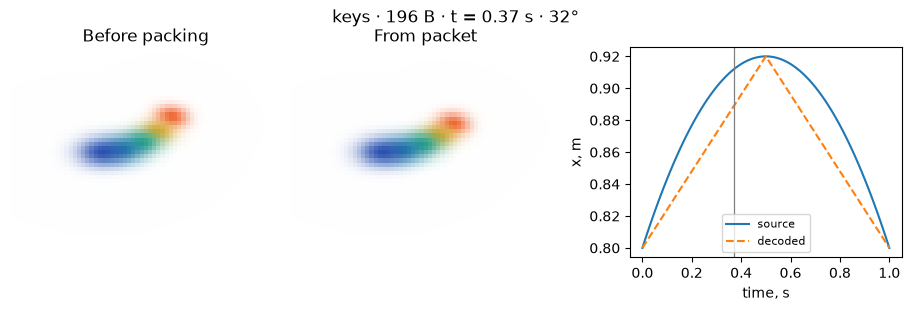

In [4]:
demos.motion_figure(lang, mode='keys', stride=8, time=.37)
plt.show()

## A signed correction

The true coordinate in that frame may have been 0.236 m. The prediction was 0.20 m, leaving a residual $r=0.236-0.20=0.036$ m. Let one code unit mean $s=0.01$ m. In code units the correction is $r/s=3.6$, with nearest integer 4. The decoded coordinate is $0.20+4\cdot0.01=0.24$ m. The remaining error is $0.004$ m. A point below the line has a negative correction.

A signed byte holds integers from −128 through 127. Here the symmetric range −127 through 127 is used. With a 0.01 m unit the largest correction is $127\cdot0.01=1.27$ m. Without saturation, rounding costs at most half a unit. A very small unit narrows the range and large residuals can clip. Anchors need no corrections. The other 14 frames take $14\cdot5\cdot3\cdot1=210$ bytes. With the anchors, that makes $196+210=406$ bytes. Each correction refers to nearby anchors, so an error in one intermediate frame does not propagate to the next.

dense 1036 B; MSE 2.2e-08 clip decode ms 0.0041
keys 196 B; MSE 0.000584908 clip decode ms 0.0679
residual 406 B; MSE 2.8e-08 clip decode ms 0.093


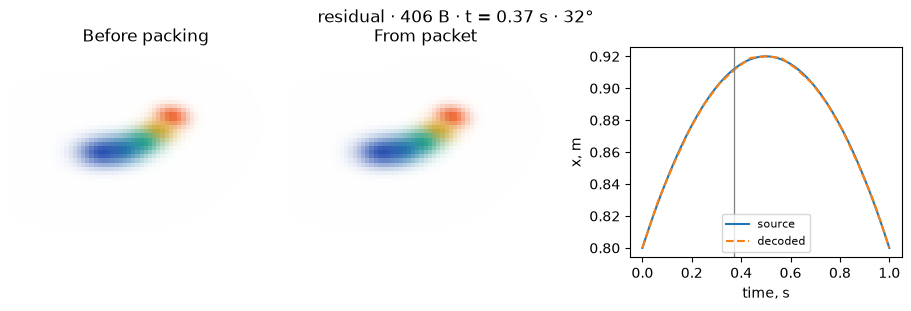

In [5]:
from deformation import scene_at
from compression_math import pose_with_centers
t, angle = .37, 32
cam = orbit_camera(angle, 55)
reference = render_scene(scene_at(model, t), cam, 65, 49)
for mode in ['dense', 'keys', 'residual']:
    data = codec.pack_motion(xyz, mode, stride=8, quantum=.002)
    track = codec.unpack_motion(data)
    pred = pose_with_centers(model['canonical'], codec.sample_track(track, t))
    error = scores(render_scene(pred, cam, 65, 49), reference)['mse']
    print(mode, len(data), 'B; MSE', round(error, 9),
          'clip decode ms', round(benchmark(lambda: codec.unpack_motion(data)), 4))
demos.motion_figure(lang, mode='residual', stride=8, quantum=.002, time=t, angle=angle)
plt.show()

## A time between frames

A time of 0.37 s maps to frame position $0.37\cdot16=5.92$. Playback mixes decoded frames 5 and 6 with weights 0.08 and 0.92. The fitted model from lesson 26 can evaluate its original curve directly at 0.37 s. Even a file with all 17 samples makes a small error between them. A 32° camera shows how that shift appears from another angle. Here MSE measures disagreement with the original **model motion**, rather than with any training photograph. The timed operation in the table decodes the whole clip. The browser times batches of short calls and divides the elapsed time by the batch length.

**Experiment.** What advantage do residuals retain at an anchor stride of one? How large is the packet?

<details>
<summary>Worked answer</summary>

All 17 frames become anchors. There are zero intermediate frames, so the corrections take zero bytes. This gives $16+17\cdot60=1036$ bytes, the same size as dense recording. Accuracy between sample times still depends on the sampling frequency.

</details>